config.json:   0%|          | 0.00/5.71k [00:00<?, ?B/s]

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


model.safetensors: reconstructing file:   0%|          |  0.00B /  898MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/741 [00:00<?, ?it/s]

processor_config.json:   0%|          | 0.00/95.0 [00:00<?, ?B/s]

preprocessor_config.json:   0%|          | 0.00/683 [00:00<?, ?B/s]

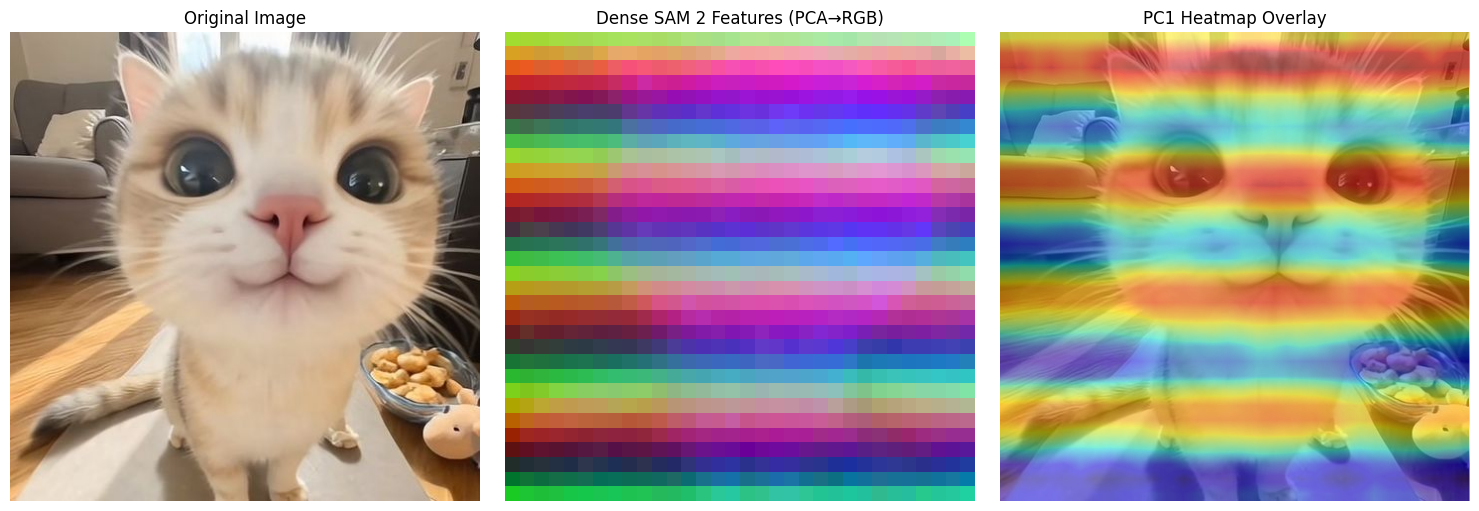

In [2]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import Sam2Model, Sam2Processor
from PIL import Image

# --- 1. Extract dense features with SAM 2 ---
# Available checkpoints: facebook/sam2-hiera-{tiny,small,base-plus,large}
# or the newer 2.1 series: facebook/sam2.1-hiera-{tiny,small,base-plus,large}
model_name = "facebook/sam2-hiera-large"
model = Sam2Model.from_pretrained(model_name).eval()
processor = Sam2Processor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    # SAM 2 returns spatial features directly: [B, H, W, D]
    vision_outputs = model.get_image_features(
        inputs["pixel_values"],
        output_hidden_states=True,
    )
    # last_hidden_state is the backbone output (pre-FPN), analogous to SAM v1's
    # hidden_states[-1] — the final transformer layer before the neck.
    features = vision_outputs.last_hidden_state  # [B, H, W, D]

# SAM 2 Hiera on 1024x1024 typically yields a 64x64 spatial grid here,
# but we read H/W dynamically so it works for any variant.
B, H, W, D = features.shape
features_np = features[0].reshape(-1, D).numpy()  # [H*W, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(features_np)  # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(H, W, 3)

# --- 3. Plot: original image, PCA-RGB map, and single-component heatmap ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense SAM 2 Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(H, W)
axes[2].imshow(image)
axes[2].imshow(
    pca1,
    cmap="jet",
    alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("sam2_dense_features.png", dpi=150)
plt.show()

[transformers] You are using a model of type `sam3_video` to instantiate a model of type `sam3_tracker`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/685 [00:00<?, ?it/s]

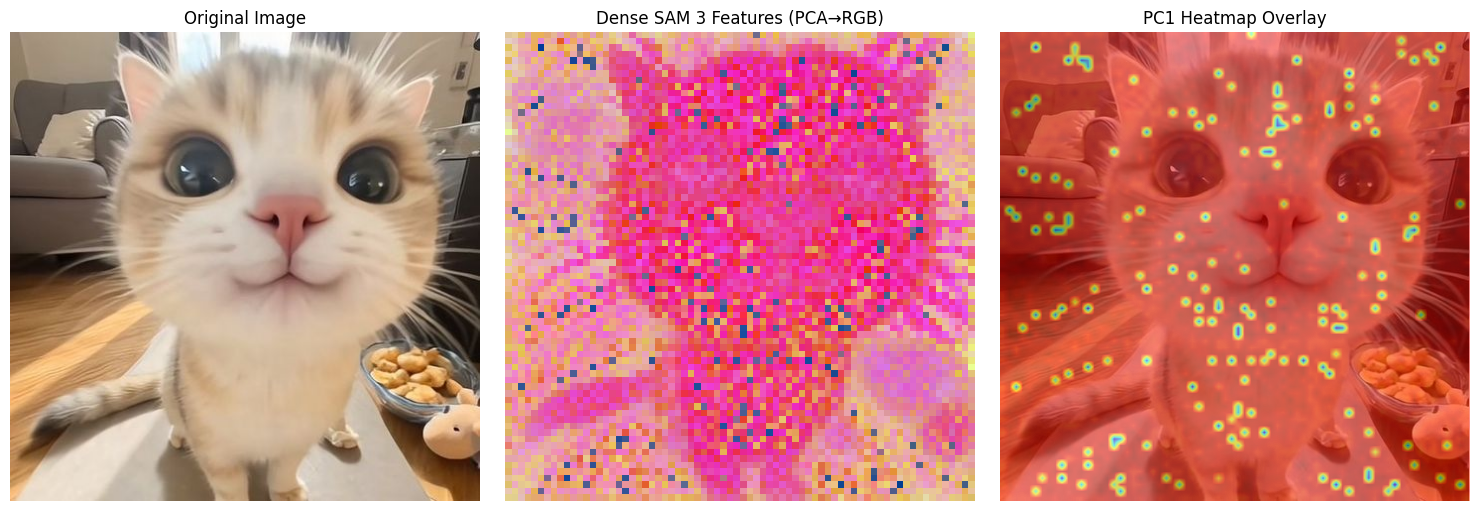

In [4]:
import torch
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from transformers import Sam3TrackerModel, Sam3TrackerProcessor
from PIL import Image
import math

# --- 1. Extract dense features with SAM 3 ---
model_name = "facebook/sam3"
model = Sam3TrackerModel.from_pretrained(model_name).eval()
processor = Sam3TrackerProcessor.from_pretrained(model_name)

image = Image.open("/content/5da360c98b9af0ad709fe18606992229.jpg").convert("RGB")
inputs = processor(images=image, return_tensors="pt")

with torch.no_grad():
    vision_outputs = model.get_image_features(
        inputs["pixel_values"],
        output_hidden_states=True,
    )
    features = vision_outputs.last_hidden_state  # Usually [B, N, D]

# -------------------------------------------------------------------------
# FIX: Handle both 3-D [B, N, D] and 4-D [B, H, W, D] outputs
# -------------------------------------------------------------------------
if features.ndim == 3:
    B, N, D = features.shape

    # Try to infer spatial dimensions.
    # ViT outputs often include a CLS token (N = H*W + 1). We handle both cases.
    h_w = int(math.sqrt(N))
    if h_w * h_w == N:
        H, W = h_w, h_w
        features = features.reshape(B, H, W, D)
    elif h_w * h_w == N - 1:
        # CLS token present: drop it, then reshape
        H, W = h_w, h_w
        features = features[:, 1:, :].reshape(B, H, W, D)
    else:
        raise ValueError(
            f"Cannot reshape {N} tokens into a square grid. "
            f"Is it rectangular (e.g. {N//64}x64)? Adjust reshape logic accordingly."
        )
elif features.ndim == 4:
    B, H, W, D = features.shape
else:
    raise ValueError(f"Unexpected feature tensor ndim: {features.ndim}")

features_np = features[0].reshape(-1, D).numpy()  # [H*W, D]

# --- 2. PCA to 3 components -> pseudo-RGB ---
pca = PCA(n_components=3)
pca_features = pca.fit_transform(features_np)  # [N, 3]

pca_features_norm = (pca_features - pca_features.min(axis=0)) / (
    pca_features.max(axis=0) - pca_features.min(axis=0) + 1e-8
)

pca_image = pca_features_norm.reshape(H, W, 3)

# --- 3. Plot ---
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].imshow(image)
axes[0].set_title("Original Image")
axes[0].axis("off")

axes[1].imshow(pca_image)
axes[1].set_title("Dense SAM 3 Features (PCA→RGB)")
axes[1].axis("off")

pca1 = pca_features_norm[:, 0].reshape(H, W)
axes[2].imshow(image)
axes[2].imshow(
    pca1,
    cmap="jet",
    alpha=0.5,
    extent=(0, image.width, image.height, 0),
    interpolation="bilinear",
)
axes[2].set_title("PC1 Heatmap Overlay")
axes[2].axis("off")

plt.tight_layout()
plt.savefig("sam3_dense_features.png", dpi=150)
plt.show()